In [1]:
   import pandas as pd

   df = pd.read_csv("../data/raw/Rest-Mex_2025_train.csv")

   print("Filas y columnas:", df.shape)
   df.head()

Filas y columnas: (208051, 6)


,Title,Review,Polarity,Town,Region,Type
0,Mi Lugar Favorito!!!!,Excelente lugar para comer y pasar una buena n...,5.0,Sayulita,Nayarit,Restaurant
1,lugares interesantes para visitar,"andar mucho, así que un poco difícil para pers...",4.0,Tulum,QuintanaRoo,Attractive
2,No es el mismo Dreams,"Es nuestra cuarta visita a Dreams Tulum, elegi...",3.0,Tulum,QuintanaRoo,Hotel
3,un buen panorama cerca de CancÃºn,"Estando en CancÃºn, fuimos al puerto y tomamos...",4.0,Isla_Mujeres,QuintanaRoo,Attractive
4,El mejor,Es un lugar antiguo y por eso me encanto tiene...,5.0,Patzcuaro,Michoacan,Hotel


In [2]:
# Nos quedamos solo con las reseñas de restaurantes
df_rest = df[df["Type"] == "Restaurant"].copy()

print("Reseñas de restaurantes:", len(df_rest))
print()
print("Cantidad por estrellas (Polarity):")
df_rest["Polarity"].value_counts().sort_index()

Reseñas de restaurantes: 86720

Cantidad por estrellas (Polarity):


Polarity
1.0     2487
2.0     2359
3.0     6002
4.0    16944
5.0    58928
Name: count, dtype: int64

In [3]:
# Quitamos las reseñas de 3 estrellas (neutrales)
df_rest = df_rest[df_rest["Polarity"] != 3].copy()

# 1-2 estrellas = negativo, 4-5 estrellas = positivo
df_rest["sentimiento"] = df_rest["Polarity"].apply(
    lambda estrellas: "positivo" if estrellas >= 4 else "negativo"
)

print("Reseñas sin las de 3 estrellas:", len(df_rest))
print()
print(df_rest["sentimiento"].value_counts())
print()
print("Porcentaje:")
print((df_rest["sentimiento"].value_counts(normalize=True) * 100).round(1))

Reseñas sin las de 3 estrellas: 80718

sentimiento
positivo    75872
negativo     4846
Name: count, dtype: int64

Porcentaje:
sentimiento
positivo    94.0
negativo     6.0
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


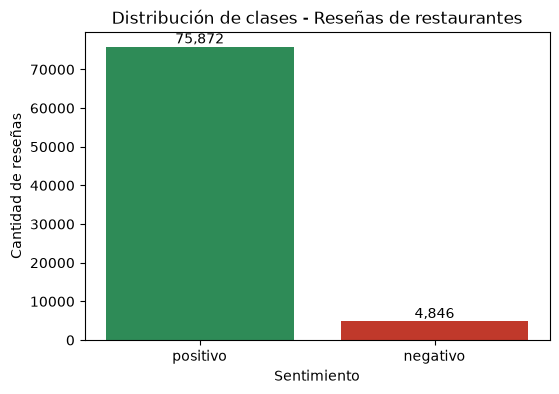

In [4]:
import matplotlib.pyplot as plt

conteo = df_rest["sentimiento"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color=["#2E8B57", "#C0392B"])
plt.title("Distribución de clases - Reseñas de restaurantes")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de reseñas")

# Escribir la cantidad encima de cada barra
for i, valor in enumerate(conteo.values):
    plt.text(i, valor, f"{valor:,}", ha="center", va="bottom")

plt.show()

In [5]:
print("Valores faltantes por columna:")
print(df_rest.isnull().sum())
print()

duplicados = df_rest.duplicated(subset=["Review"]).sum()
print("Reseñas con texto duplicado:", duplicados)

Valores faltantes por columna:
Title          1
Review         0
Polarity       0
Town           0
Region         0
Type           0
sentimiento    0
dtype: int64

Reseñas con texto duplicado: 8


In [6]:
antes = len(df_rest)

df_rest = df_rest.drop_duplicates(subset=["Review"]).copy()

print("Antes:", antes)
print("Después:", len(df_rest))
print("Eliminadas:", antes - len(df_rest))

Antes: 80718
Después: 80710
Eliminadas: 8


In [7]:
# Cantidad de palabras de cada reseña
df_rest["num_palabras"] = df_rest["Review"].str.split().str.len()

print("Estadísticas de cantidad de palabras por reseña:")
print(df_rest["num_palabras"].describe().round(1))
print()
print("Promedio por sentimiento:")
print(df_rest.groupby("sentimiento")["num_palabras"].mean().round(1))

Estadísticas de cantidad de palabras por reseña:
count    80710.0
mean        45.7
std         39.1
min          4.0
25%         25.0
50%         38.0
75%         45.0
max        999.0
Name: num_palabras, dtype: float64

Promedio por sentimiento:
sentimiento
negativo    59.7
positivo    44.8
Name: num_palabras, dtype: float64


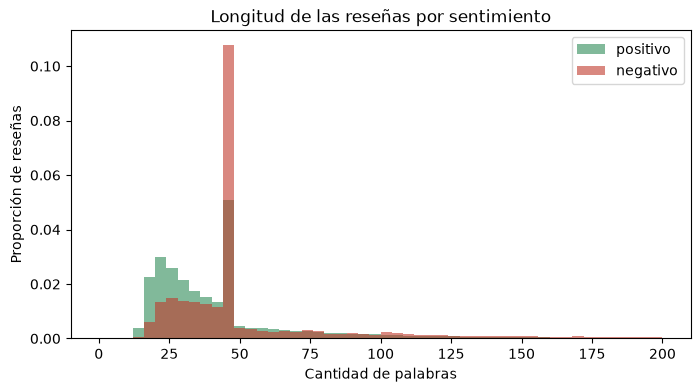

In [8]:
plt.figure(figsize=(8, 4))

for sentimiento, color in [("positivo", "#2E8B57"), ("negativo", "#C0392B")]:
    datos = df_rest[df_rest["sentimiento"] == sentimiento]["num_palabras"]
    plt.hist(datos, bins=50, range=(0, 200), alpha=0.6, color=color,
             label=sentimiento, density=True)

plt.title("Longitud de las reseñas por sentimiento")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Proporción de reseñas")
plt.legend()
plt.show()

In [9]:
from collections import Counter
import re

def contar_palabras(textos):
    contador = Counter()
    for texto in textos:
        palabras = re.findall(r"\w+", texto.lower())
        contador.update(palabras)
    return contador

conteo_total = contar_palabras(df_rest["Review"])

print("Las 20 palabras más frecuentes (sin limpiar):")
for palabra, cantidad in conteo_total.most_common(20):
    print(f"{palabra:<12} {cantidad:,}")

Las 20 palabras más frecuentes (sin limpiar):
y            163,792
de           159,947
la           134,103
el           117,180
que          80,222
en           80,142
es           67,216
muy          65,694
un           61,865
comida       48,071
a            47,330
una          44,738
con          43,504
más          43,080
los          42,743
para         40,889
lugar        37,632
no           33,336
servicio     28,324
las          25,522


In [10]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

stop_es = set(stopwords.words("spanish"))
stop_es = stop_es - {"no", "nunca", "pero", "muy", "más"}  # palabras que conservamos

def top_sin_stopwords(textos, n=15):
    conteo = contar_palabras(textos)
    return [(p, c) for p, c in conteo.most_common(300) if p not in stop_es][:n]

for sentimiento in ["positivo", "negativo"]:
    print(f"--- {sentimiento.upper()} ---")
    textos = df_rest[df_rest["sentimiento"] == sentimiento]["Review"]
    for palabra, cantidad in top_sin_stopwords(textos):
        print(f"{palabra:<12} {cantidad:,}")
    print()

--- POSITIVO ---
muy          62,925
comida       45,145
más          38,782
lugar        35,355
no           26,901
servicio     26,292
excelente    23,224
pero         17,759
buena        17,622
restaurante  15,026
mejor        12,319
atención     11,612
buen         11,334
ambiente     11,332
bien         10,378

--- NEGATIVO ---
no           6,435
más          4,298
comida       2,926
muy          2,769
pero         2,472
lugar        2,277
servicio     2,032
restaurante  1,132
si           1,050
bien         758
buena        679
pedimos      678
mesa         673
mal          666
comer        658



## Conclusiones del análisis exploratorio

- **Dataset:** 86.720 reseñas de restaurantes; se descartaron las de 3 estrellas (ambiguas) y 8 duplicadas. Quedan **80.710 reseñas**.
- **Desbalance fuerte:** 94% positivas y 6% negativas. Se tratará en la división train/test (estratificada) y en el modelado (class_weight y F1 macro).
- **Valores faltantes:** solo 1 en `Title`; la columna `Review`, que es la que se analiza, no tiene faltantes.
- **Longitud:** promedio de 46 palabras. Las reseñas negativas son más largas (59,7 vs 44,8 palabras): las malas experiencias se explican con más detalle.
- **Palabras frecuentes:** sin limpiar, dominan stop words ("y", "de", "la"), lo que justifica eliminarlas.
- **Negación:** "no" aparece 1,3 veces por reseña negativa contra 0,35 en positivas (casi 4 veces más), y "pero" el doble. Por eso **no se eliminan "no", "nunca" ni "pero"** de las stop words.
- **Palabras del dominio** como "comida", "lugar" y "servicio" aparecen en ambas clases por igual; se evaluará agregarlas como stop words.